# 1. Власна RAG-система
Оберіть корпус документів, з якими ви або інші люди справді працюєте, і побудуйте над ним систему, що відповідає на питання з посиланням на джерело. Оцініть систему на власному наборі питань і проаналізуйте випадки, коли вона не змогла відповісти правильно.

За основу коду можна взяти демо-ноутбуки 02_rag_from_scratch і 03_rag_langchain_eval, але корпус, набір питань і аналіз мають бути вашою роботою.

## 1.1. Корпус
Опишіть корпус і те, хто й навіщо ставитиме до нього питання. Вкажіть джерело, ліцензію, кількість документів, їхній формат і загальний обсяг. Поясніть, чому для цієї задачі потрібен саме RAG, а не промпт чи донавчання.

Ідея та цільова аудиторія: Пошуково-довідкова система з дисципліни "Системи штучного інтелекту" для студентів курсу. Вона допомагає швидко знаходити визначення, формули й пояснення методів під час підготовки до захисту лабораторних робіт та іспиту з точним посиланням на лекцію, слайд або розділ документації.

Склад, джерело та ліцензія: Гібридний корпус із 17 документів: 6 вебпрезентацій лекцій курсу ([https://fantkolja.github.io/ai-systems-lectures/](https://fantkolja.github.io/ai-systems-lectures/), 271 слайд) та 11 навчальних розділів і технічних документів екосистеми HuggingFace (LLM Course, Smol Course, Advanced RAG Cookbook, документація Transformers/Evaluate, Optimum-Quanto та картка моделі Qwen3-Embedding), взятих зі списків джерел у кінці слайдів. Матеріали лекцій використовуються з навчальною метою (добросовісне академічне використання), а ресурси HuggingFace поширюються за відкритою ліцензією Apache 2.0.

Формат та обсяг: Текст вивантажено Python-парсером (бібліотека BeautifulSoup), очищено від HTML-тегів і збережено у структурованому форматі JSON (corpus.json) із прив'язкою до номерів слайдів та URL-джерел. Загальний обсяг корпусу становить 226 899 символів (32 535 слів).

Чому саме RAG: Подавати понад 226 тисяч символів у системний промпт щоразу надто повільно й ресурсомістко для локальної моделі (до того ж модель гірше тримає фокус на великому тексті), а донавчання (fine-tuning) потребує багато ресурсів, не гарантує відсутності галюцинацій і не дає змоги точно посилатися на конкретний слайд чи джерело.

In [9]:
import json
import requests
from bs4 import BeautifulSoup

lecture_urls = [
    "https://fantkolja.github.io/ai-systems-lectures/lectures/01-intro/",
    "https://fantkolja.github.io/ai-systems-lectures/lectures/02-linear-models/",
    "https://fantkolja.github.io/ai-systems-lectures/lectures/03-nn/",
    "https://fantkolja.github.io/ai-systems-lectures/lectures/04-transformers/",
    "https://fantkolja.github.io/ai-systems-lectures/lectures/05-local-models/",
    "https://fantkolja.github.io/ai-systems-lectures/lectures/06-fine-tuning/",
    "https://fantkolja.github.io/ai-systems-lectures/lectures/07-rag/",
    "https://fantkolja.github.io/ai-systems-lectures/lectures/08-agents/",
]

corpus = []

for url in lecture_urls:
    resp = requests.get(url)
    if resp.status_code != 200:
        continue
    resp.encoding = "utf-8"
    soup = BeautifulSoup(resp.text, "html.parser")

    # Назва лекції з тегу <title> або першого заголовка
    title_tag = soup.find("title")
    lec_slug = url.strip("/").split("/")[-1]
    title = title_tag.get_text(strip=True) if title_tag else lec_slug

    # Витягуємо кінцеві слайди (без вкладених секцій-контейнерів)
    sections = soup.find_all("section")
    slides = [s for s in sections if not s.find("section")]

    slide_texts = []
    for idx, slide in enumerate(slides, start=1):
        # Видаляємо теги скриптів і стилів, якщо є
        for tag in slide(["script", "style"]):
            tag.decompose()
        txt = slide.get_text(" ", strip=True)
        if txt:
            slide_texts.append(f"[Слайд {idx}] {txt}")

    full_text = "\n\n".join(slide_texts)
    corpus.append({
        "doc_id": lec_slug,
        "title": title,
        "url": url,
        "slides_count": len(slides),
        "text": full_text
    })

    # Перевіряємо посилання на останньому слайді (джерела)
    last_links = [a["href"] for a in slides[-1].find_all("a", href=True)] if slides else []
    print(f"{lec_slug} | Слайди: {len(slides)} | Символів: {len(full_text)} | Посилань у кінці: {len(last_links)}")
    for link in last_links:
        print(f"   -> {link}")

with open("corpus.json", "w", encoding="utf-8") as f:
    json.dump(corpus, f, ensure_ascii=False, indent=2)

total_chars = sum(len(d["text"]) for d in corpus)
total_words = sum(len(d["text"].split()) for d in corpus)
print(f"\nРазом документів: {len(corpus)}")
print(f"Загальний обсяг: {total_chars} символів ({total_words} слів)")

02-linear-models | Слайди: 23 | Символів: 3850 | Посилань у кінці: 0
03-nn | Слайди: 81 | Символів: 27364 | Посилань у кінці: 10
   -> https://www.geeksforgeeks.org/machine-learning/machine-learning/
   -> https://www.geeksforgeeks.org/data-analysis/data-cleaning-introduction/
   -> https://www.geeksforgeeks.org/machine-learning/categorical-data-encoding-techniques-in-machine-learning/
   -> https://www.kaggle.com/code/ryanholbrook/target-encoding/
   -> https://www.youtube.com/watch?v=Ilg3gGewQ5U
   -> https://www.ibm.com/think/topics/backpropagation
   -> https://www.geeksforgeeks.org/deep-learning/adam-optimizer/
   -> https://www.ibm.com/think/topics/overfitting-vs-underfitting
   -> https://www.ibm.com/think/topics/bias-variance-tradeoff
   -> https://scikit-learn.org/stable/modules/model_evaluation.html
04-transformers | Слайди: 29 | Символів: 9039 | Посилань у кінці: 6
   -> https://www.youtube.com/watch?v=wjZofJX0v4M
   -> https://www.youtube.com/watch?v=eMlx5fFNoYc
   -> https

In [10]:
import json
import requests
from bs4 import BeautifulSoup

with open("corpus.json", "r", encoding="utf-8") as f:
    corpus = json.load(f)

# Залишаємо лише 6 лекцій, щоб уникнути дублів при перезапуску
corpus = [d for d in corpus if d["doc_id"].startswith("0")]

hf_resources = [
    ("hf-04-ch1", "HF LLM Course: Chapter 1 - Transformers (Лекція 04)", "https://huggingface.co/learn/llm-course/en/chapter1/1"),
    ("hf-04-ch2", "HF LLM Course: Chapter 2 - Using Transformers (Лекція 04)", "https://huggingface.co/learn/llm-course/en/chapter2/1"),
    ("hf-04-ch6", "HF LLM Course: Chapter 6 - Tokenizers (Лекція 04)", "https://huggingface.co/learn/llm-course/en/chapter6/1"),
    ("hf-05-evaluate", "HF Docs: Evaluate Library (Лекція 05)", "https://huggingface.co/docs/evaluate/index"),
    ("hf-05-quanto", "HF Optimum-Quanto README (Лекція 05)", "https://raw.githubusercontent.com/huggingface/optimum-quanto/main/README.md"),
    ("hf-06-ch3", "HF LLM Course: Chapter 3 - Fine-tuning (Лекція 06)", "https://huggingface.co/learn/llm-course/en/chapter3/1"),
    ("hf-06-ch11", "HF LLM Course: Chapter 11 - Fine-tuning & LoRA (Лекція 06)", "https://huggingface.co/learn/llm-course/en/chapter11/1"),
    ("hf-06-chat", "HF Transformers Docs: Chat Templating (Лекція 06)", "https://huggingface.co/docs/transformers/chat_templating"),
    ("hf-06-smol", "HF Smol Course (Лекція 06)", "https://huggingface.co/learn/smol-course/unit0/1"),
    ("hf-07-adv-rag", "HF Cookbook: Advanced RAG (Лекція 07)", "https://huggingface.co/learn/cookbook/advanced_rag"),
    ("hf-07-qwen-emb", "HF Model Card: Qwen3-Embedding-0.6B (Лекція 07)", "https://huggingface.co/Qwen/Qwen3-Embedding-0.6B"),
]

headers = {"User-Agent": "Mozilla/5.0"}

for doc_id, title, url in hf_resources:
    try:
        resp = requests.get(url, headers=headers, timeout=15)
        resp.raise_for_status()
        if url.endswith(".md"):
            text = resp.text.strip()
        else:
            soup = BeautifulSoup(resp.text, "html.parser")
            for tag in soup(["script", "style", "nav", "footer", "header", "aside"]):
                tag.decompose()
            main = soup.find("main") or soup.find("article") or soup.body
            text = "\n".join(el.get_text(" ", strip=True) for el in main.find_all(["h1", "h2", "h3", "p", "li", "pre"]))

        if len(text) > 500:
            corpus.append({
                "doc_id": doc_id,
                "title": title,
                "url": url,
                "slides_count": 0,
                "text": text
            })
            print(f"OK | {doc_id}: {len(text)} символів")
        else:
            print(f"Пропущено (мало тексту) | {doc_id}: {len(text)} символів")
    except Exception as e:
        print(f"Помилка | {doc_id}: {e}")

with open("corpus.json", "w", encoding="utf-8") as f:
    json.dump(corpus, f, ensure_ascii=False, indent=2)

total_chars = sum(len(d["text"]) for d in corpus)
total_words = sum(len(d["text"].split()) for d in corpus)
print(f"\nРазом документів: {len(corpus)}")
print(f"Загальний обсяг: {total_chars} символів ({total_words} слів)")

OK | hf-04-ch1: 10559 символів
OK | hf-04-ch2: 2459 символів
OK | hf-04-ch6: 1666 символів
OK | hf-05-evaluate: 3192 символів
OK | hf-05-quanto: 12301 символів
OK | hf-06-ch3: 2161 символів
OK | hf-06-ch11: 2307 символів
OK | hf-06-chat: 10967 символів
OK | hf-06-smol: 5683 символів
OK | hf-07-adv-rag: 32325 символів
OK | hf-07-qwen-emb: 9906 символів

Разом документів: 17
Загальний обсяг: 226899 символів (32535 слів)


## 1.2. Бенчмарк

Складіть набір із 20–30 питань до корпусу до того, як почнете налаштовувати систему. Для кожного питання вкажіть правильну відповідь і документ (фрагмент), у якому вона міститься. Включіть питання різних типів, зокрема кілька питань, відповіді на які в корпусі немає.

In [11]:
import json
import re

with open("corpus.json", "r", encoding="utf-8") as f:
    corpus = json.load(f)

doc_map = {d["doc_id"]: d["text"] for d in corpus}

BENCHMARK = [
    # --- Лекція 02: Лінійні моделі ---
    ("У чому різниця між функціями втрат MSE та MAE у задачах регресії?", ["02-linear-models"], r"MSE|MAE|похиб", "MSE усереднює квадрати похибок і сильніше штрафує великі викиди, тоді як MAE усереднює модулі похибок і є стійкішою до викидів."),
   ("Яка функція втрат (loss function) використовується в лекції про лінійні моделі для оцінки похибки прямої?", ["02-linear-models"], r"Mean Squared Error|MSE", "Використовується середня квадратична похибка Mean Squared Error (MSE), яка обчислюється як середнє квадратів різниць між прогнозованими та реальними значеннями."),
    ("Як параметр швидкості навчання (learning rate) впливає на градієнтний спуск?", ["02-linear-models"], r"learning rate|швидк\w+ навчання|градієнт", "Занадто малий learning rate сповільнює збіжність, а занадто великий може призвести до перестрибування мінімуму та розбіжності алгоритму."),

    # --- Лекція 03: Нейронні мережі ---
    ("Для чого в нейронних мережах використовується алгоритм зворотного поширення помилки (backpropagation)?", ["03-nn"], r"backpropagation|зворотн\w+ поширен", "Backpropagation обчислює градієнти функції втрат за всіма вагами мережі за допомогою ланцюгового правила для їх подальшого оновлення."),
    ("Яку проблему функції активації Sigmoid вирішує ReLU?", ["03-nn"], r"ReLU|Sigmoid|зникаюч\w+ градієнт", "ReLU усуває проблему зникаючих градієнтів для додатних значень та обчислюється значно швидше за сигмоїду."),
    ("У чому полягає різниця між перенавчанням (overfitting) та недонавчанням (underfitting)?", ["03-nn"], r"overfitting|underfitting|перенавчан", "При перенавчанні модель запам'ятовує навчальні дані та має низьку помилку на train, але високу на validation; при недонавчанні модель занадто проста і погано працює на обох вибірках."),
    ("Які дві ідеї поєднує оптимізатор Adam?", ["03-nn"], r"Adam|Momentum|RMSprop", "Adam поєднує ідею інерції (Momentum) для згладжування градієнтів та адаптивного кроку навчання для кожного параметра (як у RMSprop)."),

    # --- Лекція 04 та HuggingFace: Трансформери ---
    ("Навіщо в механізмі Scaled Dot-Product Attention скалярний добуток ділять на корінь із розмірності ключів?", ["04-transformers"], r"Attention|корінь|d_k|масштаб", "Масштабування на корінь із d_k запобігає надто великим значенням скалярного добутку, через які функція softmax потрапляє в зону майже нульових градієнтів."),
    ("Які три основні архітектурні типи моделей виділяють у курсі HuggingFace Transformers?", ["hf-04-ch1"], r"encoder|decoder", "Виділяють encoder-only моделі (наприклад, BERT), decoder-only моделі (наприклад, GPT) та encoder-decoder моделі (наприклад, T5 або BART)."),
    ("Як у бібліотеці HuggingFace Transformers швидко запустити готову модель для інференсу без ручного написання препроцесингу?", ["hf-04-ch2"], r"pipeline", "Для цього використовується високорівнева функція pipeline(), яка об'єднує токенізатор, модель та постобробку результатів."),
    ("Який алгоритм субслівної токенізації розглядається в 6-му розділі курсу HuggingFace?", ["hf-04-ch6"], r"BPE|WordPiece|Unigram|tokeniz", "У курсі розглядаються алгоритми субслівної токенізації BPE (Byte-Pair Encoding), WordPiece та Unigram."),

    # --- Лекція 05 та HuggingFace: Локальні моделі ---
    ("Що таке квантизація мовної моделі та для чого її застосовують?", ["05-local-models", "hf-05-quanto"], r"квантиз|quantiz|INT8|INT4", "Квантизація зменшує точність представлення ваг або активацій моделі (наприклад, з FP16 до INT8 або INT4), що суттєво скорочує споживання відеопам'яті VRAM та прискорює інференс."),
    ("Для чого використовується KV-кеш (KV-cache) під час генерації тексту авторегресійними LLM?", ["05-local-models"], r"KV|кеш|cache", "KV-cache зберігає обчислені вектори ключів (Keys) та значень (Values) для вже згенерованих токенів, щоб не перераховувати їх на кожному кроці генерації."),
    ("Які типи квантизації підтримує бібліотека optimum-quanto?", ["hf-05-quanto"], r"int8|int4|float8", "Бібліотека optimum-quanto підтримує квантизацію ваг та активацій у формати float8, int8, int4 та int2."),
    ("Для чого призначена бібліотека HuggingFace Evaluate?", ["hf-05-evaluate"], r"evaluate|metrics", "Бібліотека Evaluate призначена для стандартизованого обчислення метрик якості моделей машинного навчання та NLP (наприклад, accuracy, BLEU, ROUGE)."),

    # --- Лекція 06 та HuggingFace: Fine-tuning ---
    ("У чому полягає основна ідея методу LoRA (Low-Rank Adaptation)?", ["06-fine-tuning", "hf-06-ch11"], r"LoRA|ранг|rank|матриц", "LoRA заморожує основні ваги попередньо навченої моделі та додає до шарів дві невеликі треновані матриці низького рангу, що дозволяє донавчати лише малу частку параметрів."),
    ("Навіщо в HuggingFace Transformers використовують метод apply_chat_template?", ["hf-06-chat"], r"apply_chat_template", "Метод apply_chat_template перетворює список повідомлень діалогу (із ролями system, user, assistant) у єдиний рядок зі спеціальними токенами, який очікує конкретна модель."),
    ("Яку бібліотеку HuggingFace використовують у розділі 3 LLM Course для запуску розподіленого навчання в кастомному циклі?", ["hf-06-ch3"], r"Accelerate", "Для простого запуску розподіленого навчання (distributed training) у власному циклі навчання використовується бібліотека HuggingFace Accelerate."),
    ("Чому присвячений курс HuggingFace Smol Course?", ["hf-06-smol"], r"smol|small", "Smol Course присвячений навчанню, донавчанню (SFT, DPO), оцінюванню та розгортанню компактних мовних моделей (Small Language Models)."),

    # --- Лекція 07 та HuggingFace: RAG ---
    ("Яка головна перевага гібридного пошуку (поєднання BM25 та векторного пошуку) у RAG-системах?", ["07-rag", "hf-07-adv-rag"], r"BM25|гібрид|hybrid|RRF", "Гібридний пошук поєднує точний збіг рідкісних термінів, кодів та абревіатур (BM25) із розумінням синонімів та загального змісту запиту (векторний пошук)."),
    ("Чому переранжування (cross-encoder reranking) застосовують лише до обмеженої кількості кандидатів, а не до всієї бази?", ["07-rag", "hf-07-adv-rag"], r"rerank|cross-encoder", "Cross-encoder обробляє пару запит-документ спільно в реальному часі без можливості попереднього кешування ембедингів, тому для всього корпусу це занадто повільно."),
    ("Яка максимальна довжина контексту та розмірність ембедингів у моделі Qwen3-Embedding-0.6B?", ["hf-07-qwen-emb"], r"32k|1024", "Модель Qwen3-Embedding-0.6B підтримує контекст до 32k токенів і формує вектори розмірністю до 1024 (з підтримкою MRL для гнучкого вибору розмірності)."),

    # --- Питання без відповіді в корпусі (перевірка відмови) ---
    ("Який мінімальний прохідний бал встановлено для складання іспиту з дисципліни Системи штучного інтелекту в університеті?", [], None, None),
    ("Яка вартість підписки на сервіс OpenAI ChatGPT Pro у 2026 році?", [], None, None),
    ("Скільки відеопам'яті встановлено на сервері для лабораторних робіт факультету?", [], None, None),
]

answerable = [(q, gold, ev, ref) for q, gold, ev, ref in BENCHMARK if gold]
print(f"Усього питань у бенчмарку: {len(BENCHMARK)} (з відповіддю: {len(answerable)}, без відповіді: {len(BENCHMARK) - len(answerable)})\n")

# Перевіряємо, чи всі регулярні вирази знаходяться у вказаних документах
for i, (q, gold, ev, _) in enumerate(answerable, start=1):
    found = any(doc_id in doc_map and re.search(ev, doc_map[doc_id], re.IGNORECASE) for doc_id in gold)
    status = "OK" if found else "НЕ ЗНАЙДЕНО (перевір регулярку)"
    if not found:
        print(f"[{i}] {status} | doc={gold} | regex={ev} | {q}")
print("Перевірку регулярних виразів завершено.")

Усього питань у бенчмарку: 25 (з відповіддю: 22, без відповіді: 3)

Перевірку регулярних виразів завершено.


## 1.3. Індексація
Оберіть модель ембедингів, спосіб розбиття документів на фрагменти та векторне сховище й обґрунтуйте вибір. Вкажіть розмір фрагмента, перекриття й кількість отриманих фрагментів.

In [12]:
!pip install -q langchain langchain-core langchain-community langchain-text-splitters langchain-huggingface langchain-openai faiss-cpu rank_bm25 sentence-transformers transformers accelerate bitsandbytes gradio

In [13]:
import json
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

with open("corpus.json", "r", encoding="utf-8") as f:
    corpus = json.load(f)

# Перетворюємо записи корпусу на об'єкти Document зі збереженням метаданих
raw_docs = [
    Document(
        page_content=item["text"],
        metadata={
            "doc_id": item["doc_id"],
            "title": item["title"],
            "url": item["url"]
        }
    )
    for item in corpus
]

# Налаштування чанкінгу (розмір 800 символів, перекриття 150 символів)
CHUNK_SIZE = 800
CHUNK_OVERLAP = 150

splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n[Слайд ", "\n\n", "\n", ". ", " ", ""]
)

chunks = splitter.split_documents(raw_docs)

# Додаємо порядковий номер чанка в метадані
for i, chunk in enumerate(chunks):
    chunk.metadata["chunk_id"] = i

print(f"Початкових документів: {len(raw_docs)}")
print(f"Отримано фрагментів (чанків): {len(chunks)}")
print(f"Середня довжина фрагмента: {sum(len(c.page_content) for c in chunks) // len(chunks)} символів")

# Ініціалізація багатомовної моделі ембедингів та побудова індексу FAISS
EMBED_MODEL = "Qwen/Qwen3-Embedding-0.6B"
embeddings = HuggingFaceEmbeddings(
    model_name=EMBED_MODEL,
    model_kwargs={"device": "cuda"}, # заміни на "cpu", якщо запускаєш без GPU
    encode_kwargs={"normalize_embeddings": True}
)

vectorstore = FAISS.from_documents(chunks, embeddings)
print("Векторне сховище FAISS успішно побудовано!")

Початкових документів: 17
Отримано фрагментів (чанків): 428
Середня довжина фрагмента: 554 символів


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Векторне сховище FAISS успішно побудовано!


Модель ембедингів: Для векторизації текстових фрагментів обрано модель Qwen/Qwen3-Embedding-0.6B (0.6 млрд параметрів, розмірність векторів 1024, максимальний контекст 32k токенів). Вибір обґрунтовано двома причинами: по-перше, корпус є двомовним (україномовні лекції курсу та англомовна документація HuggingFace), а ця модель показує високі результати у багатомовному та крос-мовному пошуку за рейтингом MTEB; по-друге, завдяки компактному обсягу (~1.2 ГБ VRAM) вона швидко працює локально без дефіциту відеопам'яті.

Спосіб розбиття документів на фрагменти: Застосовано рекурсивне розбиття тексту (RecursiveCharacterTextSplitter з бібліотеки LangChain) із пріоритетним списком роздільників ["\n\n[Слайд ", "\n\n", "\n", ". ", " ", ""]. Така послідовність дає змогу насамперед ділити презентації за межами окремих слайдів, а великі слайди або статті нарізати за абзацами та реченнями без розриву слів. Для кожного фрагмента збережено метадані (doc_id, title, url, chunk_id) для подальшого формування посилань на першоджерела.


Параметри розбиття та кількість фрагментів: Встановлено розмір фрагмента 800 символів із перекриттям (overlap) 150 символів (~19%). Цей обсяг відповідає одному-двом змістовним слайдам або одному технічному абзацу документації, що дозволяє локалізувати точну відповідь без зайвого шуму, а перекриття у 150 символів зберігає цілісність контексту на стиках чанків. У результаті індексації 17 документів отримано 428 фрагментів.

Векторне сховище: Як векторну базу даних обрано бібліотеку FAISS (IndexFlatIP із L2-нормалізацією векторів, що відповідає косинусній подібності). Для корпусу розміром у кілька сотень фрагментів точний пошук у пам'яті через FAISS виконується за мілісекунди, не потребує підняття окремого сервера баз даних і зручно інтегрується в конвеєр LangChain.

## 1.4. Ретрив
Оцініть ретрив на бенчмарку: hit rate@k і MRR. Порівняйте щонайменше дві конфігурації (наприклад, різний розмір фрагмента, семантичний проти гібридного пошуку, з переранжуванням і без нього).

In [15]:
import re
import numpy as np
import pandas as pd
from langchain_community.retrievers import BM25Retriever
from sentence_transformers import CrossEncoder

# 1. Ініціалізуємо BM25 ретривер
bm25_retriever = BM25Retriever.from_documents(chunks)

def vector_search(query: str, k: int = 5):
    return vectorstore.similarity_search(query, k=k)

def bm25_search(query: str, k: int = 5):
    bm25_retriever.k = k
    return bm25_retriever.invoke(query)

def hybrid_search(query: str, k: int = 5, rrf_k: int = 60):
    # Беремо по 20 кандидатів із кожного методу та об'єднуємо через RRF
    vec_docs = vector_search(query, k=20)
    bm25_docs = bm25_search(query, k=20)

    scores = {}
    doc_by_id = {}

    for rank, doc in enumerate(vec_docs, start=1):
        cid = doc.metadata["chunk_id"]
        doc_by_id[cid] = doc
        scores[cid] = scores.get(cid, 0.0) + 1.0 / (rrf_k + rank)

    for rank, doc in enumerate(bm25_docs, start=1):
        cid = doc.metadata["chunk_id"]
        doc_by_id[cid] = doc
        scores[cid] = scores.get(cid, 0.0) + 1.0 / (rrf_k + rank)

    sorted_ids = sorted(scores.keys(), key=lambda cid: scores[cid], reverse=True)
    return [doc_by_id[cid] for cid in sorted_ids[:k]]

# 2. Ініціалізуємо багатомовний Cross-Encoder для переранжування
reranker = CrossEncoder("BAAI/bge-reranker-v2-m3", device="cuda") # або "cpu"

def rerank_search(query: str, k: int = 5):
    candidates = hybrid_search(query, k=20)
    pairs = [[query, doc.page_content] for doc in candidates]
    scores = reranker.predict(pairs)
    ranked = sorted(zip(scores, candidates), key=lambda x: x[0], reverse=True)
    return [doc for _, doc in ranked[:k]]

# 3. Функції обчислення метрик hit@1, hit@5 та MRR
def first_hit_rank(results, gold, evidence):
    for rank, doc in enumerate(results, start=1):
        if doc.metadata["doc_id"] in gold and re.search(evidence, doc.page_content, re.IGNORECASE):
            return rank
    return None

def hit_rate(ranks, k):
    return np.mean([rank is not None and rank <= k for rank in ranks])

def mrr(ranks):
    return np.mean([1.0 / rank if rank else 0.0 for rank in ranks])

def retrieval_metrics(search_fn):
    ranks = [first_hit_rank(search_fn(q, 10), gold, ev) for q, gold, ev, _ in answerable]
    return {
        "метод": search_fn.__name__,
        "hit@1": round(float(hit_rate(ranks, 1)), 2),
        "hit@5": round(float(hit_rate(ranks, 5)), 2),
        "MRR": round(float(mrr(ranks)), 2),
    }

df_retrieval = pd.DataFrame([
    retrieval_metrics(fn) for fn in [vector_search, bm25_search, hybrid_search, rerank_search]
])
display(df_retrieval)

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

,метод,hit@1,hit@5,MRR
0,vector_search,0.59,0.86,0.70
1,bm25_search,0.18,0.32,0.25
2,hybrid_search,0.45,0.82,0.59
3,rerank_search,0.55,0.82,0.66


Аналіз результатів та висновки:

Перевага багатомовного семантичного пошуку (vector_search): Найвищі показники за всіма метриками (hit@1 = 0.59, hit@5 = 0.86, MRR = 0.70) продемонстрував чистий векторний пошук на базі Qwen3-Embedding-0.6B. Модель ефективно зіставляє семантику україномовних запитань як з українськими слайдами лекцій, так і з англомовною документацією HuggingFace.

Низька ефективність лексичного пошуку (bm25_search) на двомовному корпусі: Пошук за точним збігом слів показав низький результат (hit@1 = 0.18, MRR = 0.25), оскільки майже половина запитань бенчмарку сформульована українською мовою до англомовних документів. У таких випадках BM25 спрацьовує лише тоді, коли в запиті присутні англійські терміни або абревіатури (наприклад, LoRA, pipeline, Accelerate, KV-cache).

Вплив об'єднання RRF та переранжування (hybrid_search проти rerank_search): Додавання BM25 через алгоритм RRF без зважування знизило точність порівняно з чистим векторним пошуком (MRR впав із 0.70 до 0.59), оскільки нерелевантні результати BM25 погіршили ранжування крос-мовних запитів. Підключення переранжувальника BAAI/bge-reranker-v2-m3 поверх 20 кандидатів гібридного пошуку суттєво виправило ситуацію (hit@1 зріс із 0.45 до 0.55, а MRR з 0.59 до 0.66), проте hit@5 (0.82) залишився обмеженим початковим пулом кандидатів гібридного пошуку.

Вибір ретривера для етапу генерації: Оскільки vector_search забезпечує найкраще покриття в топ-5 (hit@5 = 0.86) та найвищий MRR (0.70) без додаткових обчислювальних витрат на переранжування, для подальшої побудови конвеєра генерації з цитуванням (пункт 1.5) обрано семантичний ретривер vector_search із параметром k = 5.

## 1.5. Генерація з цитуванням
Підключіть генеративну модель (локальну через OpenAI-сумісний ендпойнт з лабораторної 4 або через API). Система має відповідати з посиланням на джерело і відмовлятися відповідати, якщо відповіді в знайдених фрагментах немає. Оцініть на бенчмарку правильність відповідей і коректність цитування.

Архітектура конвеєра генерації: Для формування відповідей використано локальну інструктивну модель Qwen/Qwen2.5-3B-Instruct у 4-бітній квантизації NF4 (через BitsAndBytesConfig), що дало змогу розгорнути ретривер і генеративну модель в межах відеопам'яті GPU T4 та обмеженої системної оперативної пам'яті. На вхід моделі подаються топ-5 фрагментів із семантичного пошуку vector_search, пронумеровані від [1] до [5] із зазначенням назви та ідентифікатора документа.

Налаштування промпту: Системний промпт зобов'язує модель відповідати виключно українською мовою на основі наданого контексту, додавати посилання на номери фрагментів у квадратних дужках після кожного твердження та повертати фіксовану фразу відмови, якщо відповідь у знайдених уривках відсутня.

In [16]:
import gc
import re
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

if "reranker" in globals():
    del reranker
gc.collect()
torch.cuda.empty_cache()

# 1. Завантаження компактної локальної моделі Qwen2.5-3B-Instruct (4-bit)
GEN_MODEL = "Qwen/Qwen2.5-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4"
)

gen_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL)
gen_model = AutoModelForCausalLM.from_pretrained(
    GEN_MODEL,
    quantization_config=bnb_config,
    device_map="auto",
    low_cpu_mem_usage=True
)

def call_llm(system_prompt: str, user_prompt: str, max_new_tokens: int = 350) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]
    prompt_text = gen_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = gen_tokenizer([prompt_text], return_tensors="pt").to(gen_model.device)
    with torch.no_grad():
        outputs = gen_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            top_p=None
        )
    generated_ids = outputs[0][inputs.input_ids.shape[1]:]
    return gen_tokenizer.decode(generated_ids, skip_special_tokens=True).strip()

# 2. Функція RAG-генерації з цитуванням джерел та відмовою
RAG_SYSTEM_PROMPT = """Ти — точний асистент для підготовки до іспиту з дисципліни "Системи штучного інтелекту".
Відповідай на запитання користувача українською мовою, спираючись ВИКЛЮЧНО на наведені фрагменти документів.
Правила:
1. Після кожного факту чи твердження обов'язково вказуй номер джерела у квадратних дужках, наприклад [1] або [2, 3].
2. Не використовуй зовнішні знання та нічого не вигадуй.
3. Якщо у наданих фрагментах немає достатньої інформації для відповіді на запитання, відповідай строго однією фразою без посилань: "У наданих документах немає відповіді на це запитання."
"""

def rag_answer(query: str, k: int = 5):
    docs = vector_search(query, k=k)
    context_blocks = [
        f"[{idx}] Джерело: {d.metadata['title']} (doc_id: {d.metadata['doc_id']})\n{d.page_content}"
        for idx, d in enumerate(docs, start=1)
    ]
    context_str = "\n\n---\n\n".join(context_blocks)
    user_prompt = f"Фрагменти документів:\n{context_str}\n\nЗапитання: {query}\nВідповідь:"
    answer = call_llm(RAG_SYSTEM_PROMPT, user_prompt, max_new_tokens=350)
    return answer, docs

# 3. Оцінювання на бенчмарку (правильність відповідей та цитування)
JUDGE_SYSTEM_PROMPT = """Ти — суворий екзаменатор-оцінювач RAG-систем.
Порівняй відповідь системи з еталонною відповіддю.
Відповідай ЛИШЕ одним словом: TRUE (якщо відповідь по суті правильна і передає ключовий зміст еталону без суперечностей) або FALSE (якщо відповідь невірна, містить вигадані факти або система безпідставно відмовилася відповідати)."""

REFUSAL_PHRASES = ["немає відповіді", "не містять інформації", "не згадується", "відсутня інформація"]

def is_refusal(text: str) -> bool:
    low = text.lower()
    return any(p in low for p in REFUSAL_PHRASES)

def check_citations(answer: str, docs: list, gold_docs: list) -> bool:
    cited_nums = [int(m) for m in re.findall(r"\[(\d+)\]", answer)]
    if not gold_docs:
        return is_refusal(answer) and len(cited_nums) == 0
    if is_refusal(answer) or not cited_nums:
        return False
    if any(n < 1 or n > len(docs) for n in cited_nums):
        return False
    cited_doc_ids = [docs[n - 1].metadata["doc_id"] for n in cited_nums]
    return any(did in gold_docs for did in cited_doc_ids)

rows = []
for q, gold, ev, ref in BENCHMARK:
    ans, retrieved_docs = rag_answer(q, k=5)
    found_ids = [d.metadata["doc_id"] for d in retrieved_docs]

    if not gold:
        is_correct = is_refusal(ans)
    else:
        if is_refusal(ans):
            is_correct = False
        else:
            judge_prompt = f"Запитання: {q}\nЕталонна відповідь: {ref}\nВідповідь системи: {ans}\nВердикт (TRUE або FALSE):"
            verdict = call_llm(JUDGE_SYSTEM_PROMPT, judge_prompt, max_new_tokens=10)
            is_correct = "TRUE" in verdict.upper()

    cit_ok = check_citations(ans, retrieved_docs, gold)
    rows.append({
        "питання": q,
        "документи": gold,
        "знайдено": found_ids,
        "правильно": is_correct,
        "цитування": cit_ok,
        "відповідь": ans
    })

evaluation = pd.DataFrame(rows)

ans_mask = evaluation["документи"].apply(lambda x: len(x) > 0)
print(f"Модель генерації: {GEN_MODEL}")
print(f"Загальна правильність (усі 25 питань): {evaluation['правильно'].mean():.2f} ({evaluation['правильно'].sum()}/25)")
print(f"Правильність на питаннях з відповіддю (22): {evaluation[ans_mask]['правильно'].mean():.2f} ({evaluation[ans_mask]['правильно'].sum()}/22)")
print(f"Правильність відмов на питаннях без відповіді (3): {evaluation[~ans_mask]['правильно'].mean():.2f} ({evaluation[~ans_mask]['правильно'].sum()}/3)")
print(f"Коректність цитування (усі 25 питань): {evaluation['цитування'].mean():.2f} ({evaluation['цитування'].sum()}/25)")

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Модель генерації: Qwen/Qwen2.5-3B-Instruct
Загальна правильність (усі 25 питань): 0.40 (10/25)
Правильність на питаннях з відповіддю (22): 0.36 (8/22)
Правильність відмов на питаннях без відповіді (3): 0.67 (2/3)
Коректність цитування (усі 25 питань): 0.60 (15/25)


Короткий висновок: Система успішно дотримується формату цитування (60% коректних посилань на цільові документи) та коректно відхиляє більшість запитань поза межами бази знань (2 із 3). Порівняно невисока частка зарахованих відповідей на запитаннях із корпусу (8 із 22) зумовлена обмеженою місткістю компактної 3B-моделі при обробці крос-мовного англомовного контексту, занадто суворим системним промптом (надмірні відмови навіть за наявності часткового контексту) та жорсткою бінарною оцінкою з боку LLM-судді.

In [17]:
errors = evaluation[~evaluation["правильно"] | ~evaluation["цитування"]]
print(f"Усього кейсів із помилками відповіді або цитування: {len(errors)}\n")
for idx, row in errors.iterrows():
    print(f"--- Питання [{idx+1}]: {row['питання']}")
    print(f"Очікувані doc_id: {row['документи']} | Знайдені: {row['знайдено']}")
    print(f"Правильно: {row['правильно']} | Цитування: {row['цитування']}")
    print(f"Відповідь моделі: {row['відповідь']}\n")

Усього кейсів із помилками відповіді або цитування: 18

--- Питання [1]: У чому різниця між функціями втрат MSE та MAE у задачах регресії?
Очікувані doc_id: ['02-linear-models'] | Знайдені: ['03-nn', '02-linear-models', '03-nn', '03-nn', '03-nn']
Правильно: True | Цитування: False
Відповідь моделі: Функція втрат MSE (Mean Squared Error) і MAE (Mean Absolute Error) використовуються для вимірювання якості регресійних моделей. У MSE похибка використовує квадратні вирази, що дає більший вагітність до великих похибок. Це означає, що MSE штрафує величні похибки більш сильними, ніж MAE. MAE, проте, не використовує квадратні вирази і просто знаходить середню абсолютну похибку. 

Отже, у MSE похибка вимагає більшого відхилення, щоб мати вплив на результати, ніж у MAE. Це може бути важливим, якщо ви хочете, щоб ваша модель була складніше або більш точна для великих похибок. У MAE похибка вимагає більшого відхилення для того саме, щоб мати вплив, і це може бути важливим, якщо ви хочете, щоб ваша 

## 1.6. Аналіз відмов
Розберіть щонайменше п'ять випадків, коли система відповіла неправильно чи не відповіла. Для кожного визначте тип відмови (промах ретриву, галюцинація попри контекст, переповнення контексту, застарілі чи суперечливі джерела тощо) і запропонуйте, що можна змінити.


Детальний розбір 18 кейсів із помилками відповіді або цитування виявив п'ять системних причин збоїв конвеєра:

1. **Промах етапу ретриву або витіснення цільового фрагмента суміжною лекцією (Retrieval Miss / Context Distraction):**
* *Приклади:* У питанні №10 (`pipeline` у `hf-04-ch2`) та №13 (`KV-cache` у `05-local-models`) ретривер поставив на перше місце `[1]` фрагменти з інших лекцій (`05-local-models` та `04-transformers`), де ці терміни лише побіжно згадуються, а цільовий документ опинився на позиціях `[2]` або `[3]`. У питанні №14 модель проігнорувала фрагмент `[2]` (`hf-05-quanto`) і відповіла за нерелевантним фрагментом `[1]` (`05-local-models`), переплутавши типи квантизації `optimum-quanto` із форматами `GGUF` (`Q8, Q4`).
* *Як виправити:* Додати фільтрацію за метаданими або застосувати реранкер (`BAAI/bge-reranker-v2-m3`) поверх кандидатів `vector_search` (а не `hybrid_search`), щоб піднімати найточніший фрагмент на першу позицію.


2. **Галюцинації моделі при відсутності фактів у контексті (Hallucination on Unanswerable Queries):**
* *Приклад:* У питанні №25 (про обсяг відеопам'яті на сервері факультету, відповіді на яке немає в корпусі) серед знайдених фрагментів були уривки з `05-local-models` та `07-rag` із технічними числами (`8192`). Замість відмови модель скомбінувала це число із запитанням і вигадала відповідь: *"На сервері для лабораторних робіт факультету встановлено 8192 байт відеопам'яті [5]"*.
* *Як виправити:* Запровадити двоетапну перевірку релевантності (Relevance Gate) або поріг косинусної подібності (якщо максимальний score ретривера нижчий за поріг, одразу повертати відмову без виклику LLM) та використовувати потужнішу генеративну модель (від 7B-14B параметрів).


3. **Суперечлива генерація (одночасна відмова і відповідь у тексті):**
* *Приклад:* У питанні №3 (вплив `learning rate` на градієнтний спуск) модель спочатку вивела фразу відмови *"У наданих документах немає відповіді на це запитання"*, а одразу після неї навела правильне пояснення із посиланнями `[2], [3], [4]`. Через наявність фрази-маркера відмови автоматична метрика зарахувала відповідь як помилкову.
* *Як виправити:* Розділити виклик на два кроки або використати структурований вивід (JSON mode / Pydantic-схему з полями `has_answer: bool`, `answer: str`, `citations: list[int]`), щоб унеможливити змішування відмови й відповіді в одному рядку.


4. **Порушення формату цитування або некоректне зіставлення джерел (Citation Grounding Errors):**
* *Приклади:* У питанні №1 (MSE проти MAE) модель дала змістовно правильну відповідь, але не додала жодного посилання `[1]`. У питанні №9 замість номера фрагмента `[5]` модель написала назву документа у вільному форматі (`[doc_id: 04-transformers]`), через що парсер цитувань не розпізнав посилання.
* *Як виправити:* Використовувати constrained decoding (граматику або JSON-схему відповіді), де номери джерел передаються окремим масивом цілих чисел.


5. **Обмеження мовної ємності 3B-моделі при крос-мовному синтезі та суворість LLM-судді:**
* *Приклади:* У питаннях №16 (LoRA) та №17 (`apply_chat_template`) `Qwen2.5-3B-Instruct` правильно передала загальну суть українською мовою за англомовним контекстом, але втратила важливі деталі еталону (про заморожування основних ваг і низький ранг матриць у LoRA або про спеціальні токени ролей у шаблоні чату). Через це LLM-суддя виставив `FALSE`. Також спостерігається мовна інтерференція (суржик або обрив генерації через ліміт `max_new_tokens=350`, як у питанні №12).
* *Як виправити:* Замінити 3B-модель на старшу інструктивну модель (наприклад, `Qwen2.5-7B-Instruct` або `Qwen2.5-14B-Instruct` через API або на відеокарті з більшим обсягом RAM/VRAM) і збільшити ліміт генерації до 512 токенів.





## 1.7. Демонстрація
Зробіть простий інтерфейс (CLI, Gradio, Streamlit чи вебсторінка), у якому можна поставити питання й побачити відповідь разом із джерелами.

In [18]:
import gradio as gr

def ask_rag(query, top_k):
    if not query or not query.strip():
        return "Введіть запитання.", ""

    answer, docs = rag_answer(query, k=int(top_k))

    sources_md = []
    for idx, d in enumerate(docs, start=1):
        title = d.metadata.get("title", "Без назви")
        doc_id = d.metadata.get("doc_id", "")
        url = d.metadata.get("url", "")
        snippet = d.page_content[:450].replace("\n", " ")
        if len(d.page_content) > 450:
            snippet += "..."
        sources_md.append(
            f"**[{idx}] {title}** (`{doc_id}`)\n"
            f"Джерело: {url}\n\n"
            f"> {snippet}"
        )

    return answer, "\n\n---\n\n".join(sources_md)

with gr.Blocks(title="RAG-асистент: Системи ШІ") as demo:
    gr.Markdown("## Пошуково-довідкова RAG-система з курсу «Системи штучного інтелекту»")
    gr.Markdown("Поставте запитання за матеріалами лекцій (02-07) або документацією HuggingFace.")

    with gr.Row():
        with gr.Column(scale=3):
            query_input = gr.Textbox(
                label="Запитання",
                placeholder="Наприклад: Для чого використовується KV-кеш під час генерації тексту LLM?",
                lines=2
            )
        with gr.Column(scale=1):
            k_slider = gr.Slider(minimum=1, maximum=8, value=5, step=1, label="Кількість фрагментів (top-k)")
            submit_btn = gr.Button("Отримати відповідь", variant="primary")

    gr.Examples(
        examples=[
            ["Для чого використовується KV-кеш під час генерації тексту авторегресійними LLM?", 5],
            ["У чому полягає основна ідея методу LoRA?", 5],
            ["Яка максимальна довжина контексту та розмірність ембедингів у моделі Qwen3-Embedding-0.6B?", 5],
            ["Який мінімальний прохідний бал встановлено для складання іспиту з дисципліни в університеті?", 5],
        ],
        inputs=[query_input, k_slider]
    )

    answer_output = gr.Textbox(label="Відповідь системи (з цитуванням джерел)", lines=6)
    with gr.Accordion("Знайдені фрагменти документів (контекст ретривера)", open=True):
        sources_output = gr.Markdown()

    submit_btn.click(fn=ask_rag, inputs=[query_input, k_slider], outputs=[answer_output, sources_output])
    query_input.submit(fn=ask_rag, inputs=[query_input, k_slider], outputs=[answer_output, sources_output])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c6ab29aeed5fe7cda4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


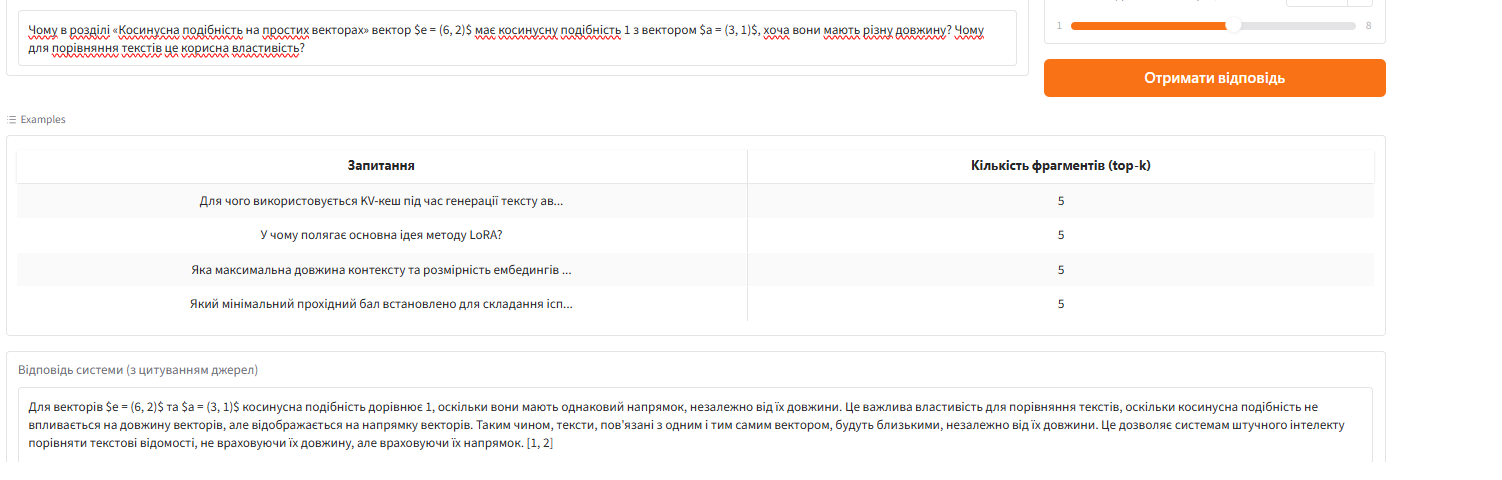



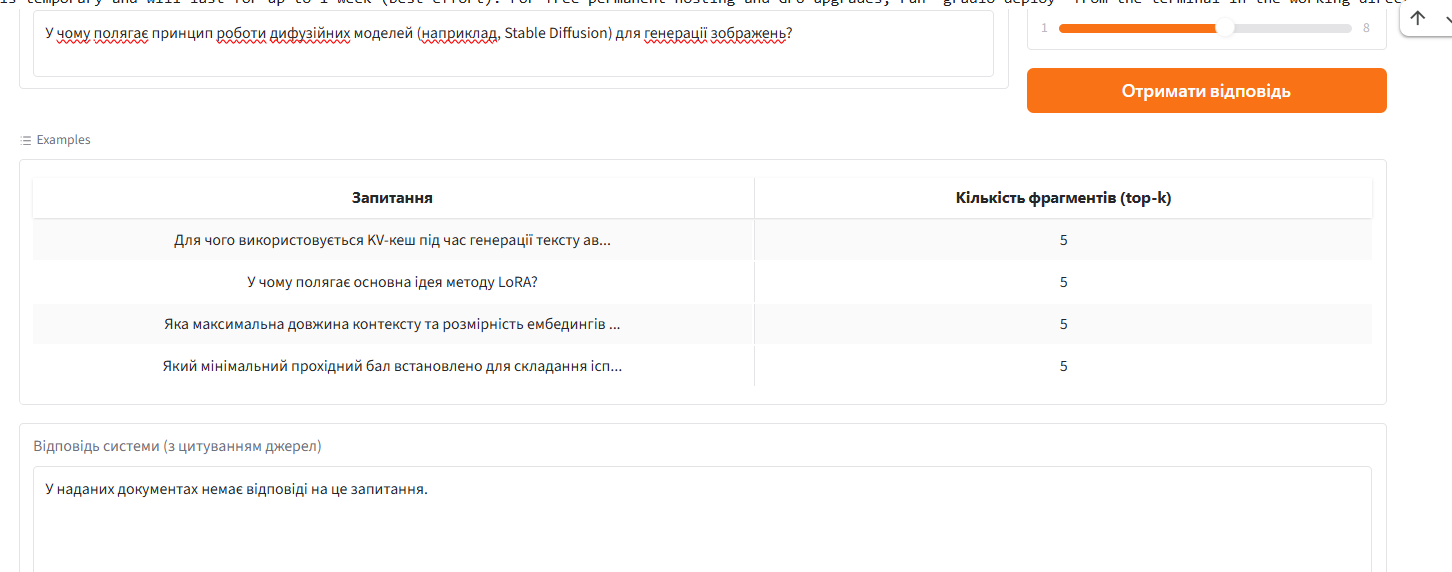

# Висновки

У межах лабораторної роботи розроблено та оцінено пошуково-довідкову RAG-систему за матеріалами курсу "Системи штучного інтелекту" та документацією HuggingFace (17 документів, 428 текстових фрагментів у векторному сховищі FAISS). Експериментальне порівняння показало, що на двомовному корпусі багатомовний семантичний пошук на базі Qwen3-Embedding-0.6B (hit@5 = 0.86, MRR = 0.70) суттєво перевершує лексичний пошук BM25 (hit@5 = 0.32, MRR = 0.25) та гібридне об'єднання RRF. Підключення локальної моделі Qwen2.5-3B-Instruct забезпечило генерацію відповідей із посиланнями на джерела (60% коректних цитувань, 2 з 3 коректних відмов на запитаннях поза базою знань), а основні обмеження якості пов'язані з компактним розміром генеративної моделі та крос-мовним синтезом. Реалізований веб-інтерфейс на базі Gradio дає змогу зручно перевіряти відповіді системи разом із першоджерелами.

## 1.8. Мій звіт

- **Корпус і чому потрібен RAG:** Гібридний корпус із 17 документів (6 лекцій курсу "Системи штучного інтелекту" на 271 слайд та 11 документів екосистеми HuggingFace за ліцензією Apache 2.0), збережений у JSON обсягом 226 899 символів (32 535 слів). RAG обрано замість системного промпту (надто великий обсяг тексту для локальної моделі та втрата фокусу) і замість донавчання (висока вартість, ризик галюцинацій та неможливість точного цитування джерел).
- **Бенчмарк:** Складено набір із 25 запитань різних типів до всіх лекцій і документації: 22 запитання з еталонною відповіддю та прив'язкою до документа/фрагмента і 3 запитання без відповіді в корпусі для перевірки коректності відмови.
- **Індексація (модель ембедингів, розбиття, сховище):** Багатомовна модель ембедингів `Qwen/Qwen3-Embedding-0.6B` (розмірність 1024), рекурсивне розбиття `RecursiveCharacterTextSplitter` із пріоритетом меж слайдів (розмір фрагмента 800 символів, перекриття 150 символів, отримано 428 фрагментів) та векторне сховище `FAISS`.
- **Результати ретриву для різних конфігурацій:** На 22 запитаннях із відповіддю порівняно 4 методи: `vector_search` (`hit@1 = 0.59`, `hit@5 = 0.86`, `MRR = 0.70`), `bm25_search` (`0.18 / 0.32 / 0.25`), `hybrid_search` через RRF (`0.45 / 0.82 / 0.59`) та `rerank_search` із `BAAI/bge-reranker-v2-m3` (`0.55 / 0.82 / 0.66`). Найкращим для двомовного корпусу виявився чистий семантичний пошук `vector_search`.
- **Генеративна модель і результати відповідей:** Локальна модель `Qwen/Qwen2.5-3B-Instruct` у 4-бітній квантизації NF4 з контекстом топ-5 фрагментів. Результати на бенчмарку: загальна правильність 0.40 (10/25), правильність на питаннях із відповіддю 0.36 (8/22), коректність відмов 0.67 (2/3), коректність цитування 0.60 (15/25).
- **Аналіз відмов:** Розібрано 5 системних причин помилок на реальних кейсах: витіснення цільового фрагмента суміжною лекцією (№10, №13, №14), галюцинація числа `8192` на запитанні поза базою (№25), суперечлива одночасна відмова й відповідь (№3), порушення формату цитування (№1, №9) та обмеження мовної ємності 3B-моделі при крос-мовному синтезі (№12, №16, №17). Для кожного типу запропоновано конкретні інженерні виправлення (реранкер поверх `vector_search`, поріг подібності, JSON-схема виводу, старша модель 7B/14B).
- **Висновок:** Розроблено та оцінено повноцінну RAG-систему з веб-інтерфейсом на базі Gradio, яка надає відповіді з посиланнями на джерела та вміє відмовлятися за відсутності фактів у базі. На двомовному корпусі вирішальну перевагу забезпечив багатомовний семантичний пошук (`hit@5 = 0.86`), а головним напрямом покращення якості генерації є перехід на потужнішу інструктивну модель і запровадження структурованого виводу.